# 03 · IRT and the cold start
**Kuizi brain walkthrough, notebook 3 of 10**

**Item Response Theory** (IRT) is the classic model of exams. Each student gets one number,
their **ability** θ (theta). Each item gets a **difficulty** b and a **discrimination** a (how
sharply it separates weak from strong students). The chance of a right answer is

  P(right) = sigmoid( a × (θ − b) )

When θ = b the chance is 50 %. IRT is simple and robust, but it ignores time and learning.

Kuizi uses IRT for the **cold start**: a brand-new student has no history, so SAINT+ cannot say
much yet. A 12-question **placement test** gives a first estimate of θ, then the brain takes over.

| In this notebook | Production ticket |
| --- | --- |
| IRT estimator and hand-off to SAINT+ | T043 |
| 12-question placement test at onboarding | T175 |
| Item calibration on pilot data | T044 |

<div dir="rtl" lang="ar">

## ٠٣ · نظرية الاستجابة للمفردة (IRT) والبداية الباردة

IRT هي النموذج الكلاسيكي للامتحانات. لكل تلميذ رقم واحد هو <b>قدرته</b> θ، ولكل تمرين <b>صعوبة</b> b و<b>قدرة تمييز</b> a.
احتمال الإجابة الصحيحة هو sigmoid(a × (θ − b)): عندما تساوي القدرة الصعوبة يكون الاحتمال 50%.
IRT بسيطة ومتينة لكنها تتجاهل الزمن والتعلّم.

يستعمل كويزي IRT في <b>البداية الباردة</b>: التلميذ الجديد ليس له تاريخ، فلا يستطيع SAINT+ أن يقول الكثير.
<b>اختبار تحديد المستوى</b> من 12 سؤالًا يعطي تقديرًا أوليًا لـθ، ثم يتولّى الدماغ.

</div>

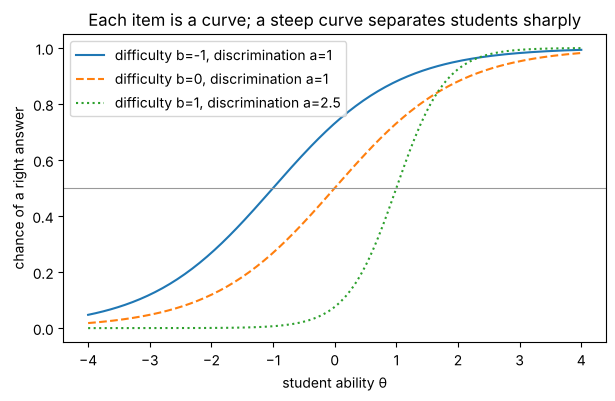

In [1]:
# Concept: the logistic curve behind IRT · Production: T043
import numpy as np, matplotlib.pyplot as plt
theta = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(figsize=(7, 4))
for b, a, style in [(-1, 1, "-"), (0, 1, "--"), (1, 2.5, ":")]:
    ax.plot(theta, 1 / (1 + np.exp(-a * (theta - b))), style, label=f"difficulty b={b}, discrimination a={a}")
ax.axhline(.5, color="#999", lw=.8)
ax.set_xlabel("student ability θ"); ax.set_ylabel("chance of a right answer")
ax.legend(); ax.set_title("Each item is a curve; a steep curve separates students sharply")
plt.show()

In [2]:
# Concept: fitting IRT on real answers · Production: T043, T044
from kuizi_brain import data as D, models as M, metrics as X
import torch
df = D.load_assist2009()
train, test = D.split_by_student(df)
irt = M.IRT(df.student.max() + 1, df.item.max() + 1)
irt.fit(train.student.values, train.item.values, train.correct.values, epochs=300)
b, a = irt.item_params()
seen = np.zeros(len(b), bool); seen[train.item.unique()] = True
b[~seen], a[~seen] = 0.0, 1.0   # items never seen in training: neutral defaults
print(f"{seen.sum():,} items calibrated; difficulty from {b[seen].min():.1f} to {b[seen].max():.1f}")

/home/user/kuizi/ml/kuizi_brain/models.py:130: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  student, item = torch.as_tensor(student).long(), torch.as_tensor(item).long()


15,495 items calibrated; difficulty from -5.1 to 5.6


## Cold start: how many answers until we know a new student?

For each **test** student (never seen in training) we estimate θ from their first *k* answers,
with Bayes' rule and a normal prior (most students are average), then predict all their later
answers. With k = 0 we only know the item difficulty.

<div dir="rtl" lang="ar">

## البداية الباردة: كم إجابة نحتاج لنعرف تلميذًا جديدًا؟

لكل تلميذ في <b>مجموعة الاختبار</b> (لم يره النموذج أثناء التدريب) نقدّر θ من أول <i>k</i> إجابات بقاعدة بايز
مع افتراض أن أغلب التلاميذ متوسّطون، ثم نتنبّأ بكل إجاباته اللاحقة. عندما k = 0 لا نعرف إلا صعوبة التمارين.

</div>

/home/user/kuizi/ml/kuizi_brain/models.py:156: RuntimeWarning: divide by zero encountered in log
  log_post += np.log(p if y else 1 - p)
/home/user/kuizi/ml/kuizi_brain/models.py:155: RuntimeWarning: overflow encountered in exp
  p = 1 / (1 + np.exp(-a[i] * (grid - b[i])))
/tmp/ipykernel_1582/1069069293.py:9: RuntimeWarning: overflow encountered in exp
  ps.append(1 / (1 + np.exp(-a[rest.item.values] * (th - b[rest.item.values]))))
/home/user/kuizi/ml/kuizi_brain/models.py:156: RuntimeWarning: divide by zero encountered in log
  log_post += np.log(p if y else 1 - p)
/home/user/kuizi/ml/kuizi_brain/models.py:155: RuntimeWarning: overflow encountered in exp
  p = 1 / (1 + np.exp(-a[i] * (grid - b[i])))
/tmp/ipykernel_1582/1069069293.py:9: RuntimeWarning: overflow encountered in exp
  ps.append(1 / (1 + np.exp(-a[rest.item.values] * (th - b[rest.item.values]))))
/home/user/kuizi/ml/kuizi_brain/models.py:155: RuntimeWarning: overflow encountered in exp
  p = 1 / (1 + np.exp(-a[i] * (grid -

/tmp/ipykernel_1582/1069069293.py:9: RuntimeWarning: overflow encountered in exp
  ps.append(1 / (1 + np.exp(-a[rest.item.values] * (th - b[rest.item.values]))))
/home/user/kuizi/ml/kuizi_brain/models.py:155: RuntimeWarning: overflow encountered in exp
  p = 1 / (1 + np.exp(-a[i] * (grid - b[i])))
/home/user/kuizi/ml/kuizi_brain/models.py:156: RuntimeWarning: divide by zero encountered in log
  log_post += np.log(p if y else 1 - p)
/tmp/ipykernel_1582/1069069293.py:9: RuntimeWarning: overflow encountered in exp
  ps.append(1 / (1 + np.exp(-a[rest.item.values] * (th - b[rest.item.values]))))
/home/user/kuizi/ml/kuizi_brain/models.py:155: RuntimeWarning: overflow encountered in exp
  p = 1 / (1 + np.exp(-a[i] * (grid - b[i])))
/home/user/kuizi/ml/kuizi_brain/models.py:156: RuntimeWarning: divide by zero encountered in log
  log_post += np.log(p if y else 1 - p)
/tmp/ipykernel_1582/1069069293.py:9: RuntimeWarning: overflow encountered in exp
  ps.append(1 / (1 + np.exp(-a[rest.item.values

/home/user/kuizi/ml/kuizi_brain/models.py:155: RuntimeWarning: overflow encountered in exp
  p = 1 / (1 + np.exp(-a[i] * (grid - b[i])))
/home/user/kuizi/ml/kuizi_brain/models.py:156: RuntimeWarning: divide by zero encountered in log
  log_post += np.log(p if y else 1 - p)
/tmp/ipykernel_1582/1069069293.py:9: RuntimeWarning: overflow encountered in exp
  ps.append(1 / (1 + np.exp(-a[rest.item.values] * (th - b[rest.item.values]))))


after  0 answers: AUC 0.633
after  1 answers: AUC 0.638
after  2 answers: AUC 0.640
after  4 answers: AUC 0.655
after  6 answers: AUC 0.676
after  8 answers: AUC 0.680
after 12 answers: AUC 0.691


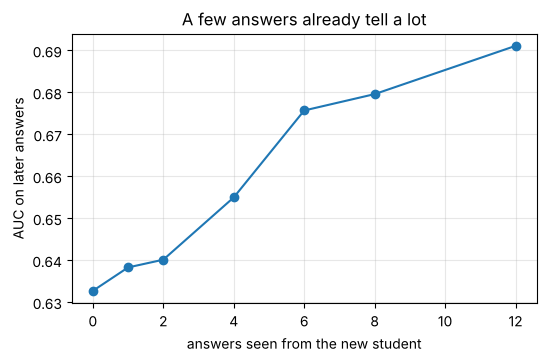

In [3]:
# Concept: cold-start curve: AUC after k answers · Production: T043, T175
results = []
groups = [g for _, g in test.groupby("student") if len(g) > 15]
for k in [0, 1, 2, 4, 6, 8, 12]:
    ys, ps = [], []
    for g in groups:
        first, rest = g.iloc[:k], g.iloc[15:]
        th, _ = M.estimate_ability(first.item.values, first.correct.values, b, a)
        ps.append(1 / (1 + np.exp(-a[rest.item.values] * (th - b[rest.item.values]))))
        ys.append(rest.correct.values)
    y, p = np.concatenate(ys), np.concatenate(ps)
    results.append((k, X.auc(y, p)))
for k, v in results:
    print(f"after {k:2d} answers: AUC {v:.3f}")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(*zip(*results), marker="o")
ax.set_xlabel("answers seen from the new student"); ax.set_ylabel("AUC on later answers")
ax.set_title("A few answers already tell a lot"); ax.grid(alpha=.3)
plt.show()

## Which 12 questions? The adaptive placement test

Asking random questions wastes time: a strong student learns nothing from easy items. An
**adaptive** test asks, each time, the item with the most **information** at the current
estimate: the item whose answer is hardest to predict. Below we simulate students with a known
true ability and compare the error after 12 questions.

<div dir="rtl" lang="ar">

## أي 12 سؤالًا؟ اختبار تحديد المستوى التكيّفي

الأسئلة العشوائية تضيّع الوقت: التلميذ القوي لا يكشف شيئًا في التمارين السهلة. الاختبار <b>التكيّفي</b> يطرح كل مرة
التمرين الذي يحمل أكبر قدر من <b>المعلومات</b> عند التقدير الحالي، أي التمرين الذي يصعب توقّع إجابته.
نحاكي أدناه تلاميذ قدرتهم الحقيقية معروفة ونقارن الخطأ بعد 12 سؤالًا.

</div>

In [4]:
# Concept: adaptive vs random placement (Fisher information) · Production: T175, T043
rng = np.random.default_rng(0)
# Only well-calibrated items: answered at least 50 times in training, with a moderate slope.
counts = np.bincount(train.item.values, minlength=len(b))
pool = np.flatnonzero((counts >= 50) & (a > 0.3) & (a < 2.5))
print(f"placement pool: {len(pool):,} well-calibrated items")
def placement(true_theta, adaptive):
    asked, answers = [], []
    for _ in range(12):
        est, _ = M.estimate_ability(asked, answers, b, a)
        candidates = np.setdiff1d(pool, asked)
        if adaptive:
            item = candidates[np.argmax(M.item_information(est, b[candidates], a[candidates]))]
        else:
            item = rng.choice(candidates)
        p = 1 / (1 + np.exp(-a[item] * (true_theta - b[item])))
        asked.append(item); answers.append(int(rng.random() < p))
    return M.estimate_ability(asked, answers, b, a)[0]
errors = {"random": [], "adaptive": []}
for true_theta in rng.normal(0, 1, 200):
    for mode in errors:
        errors[mode].append(abs(placement(true_theta, mode == "adaptive") - true_theta))
for mode, e in errors.items():
    print(f"{mode:8s}: average error on ability after 12 questions = {np.mean(e):.2f}")

placement pool: 355 well-calibrated items


random  : average error on ability after 12 questions = 0.34
adaptive: average error on ability after 12 questions = 0.22


### Remember
- IRT: one ability per student, one difficulty (and discrimination) per item, a logistic curve between them.
- It cannot see learning or forgetting, which is why the brain is SAINT+ and not IRT.
- It is excellent for the **cold start**: a short adaptive test gives a first estimate, then SAINT+ takes over (T043).

<div dir="rtl" lang="ar">

### تذكّر
- IRT: قدرة واحدة لكل تلميذ، وصعوبة (وتمييز) لكل تمرين، ومنحنى لوجستي بينهما.
- لا ترى التعلّم ولا النسيان، ولهذا الدماغ هو SAINT+ وليس IRT.
- ممتازة في <b>البداية الباردة</b>: اختبار تكيّفي قصير يعطي تقديرًا أوليًا، ثم يتولّى SAINT+ (T043).

</div>